# Normal-mode analysis: a 1D hydrodynamic toy model

Adapted from `NMA_python_full_Mikic.ipynb`: **same variable ordering** $(\rho_1,v_1,T_1)$, staggered-grid derivatives, block matrix, and dense eigenvalue solve. We remove the Mikić simulation dependencies, flows, gravity and loop expansion. Two cases: **adiabatic** and **thermal conduction + optically thin radiative losses**.

**Units:** nondimensional, with ideal gas law $p=\rho T$ (gas constant set to 1). The HDF5 input contains the equilibrium arrays `s`, `rho0`, `T0`; `p0=rho0*T0`. The background is **uniform**, static, and maintained in thermal equilibrium by constant heating. For arbitrary nonuniform backgrounds, additional equilibrium constraints and linearized terms are necessary; this notebook deliberately rejects them.

**Boundary conditions:** selectable `line_tied` ($v_1=T_1=0$) or `reflecting` ($v_1=0$, $\partial_s T_1=\partial_s\rho_1=0$). The reflecting density condition is a pedagogical constraint and needs physical scrutiny for compressible waves. The staggered operators follow the original notebook, including its second-order wall stencil for $\partial_s v_1$.

The solver resolution `N` is independent of the input HDF5 sampling; profiles are interpolated to a uniform nodal grid before operator construction.

In [1]:
import numpy as np
import h5py
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.linalg import eig

GAMMA = 5/3
INPUT_FILE = Path('nma_example_background.h5')  # place supplied HDF5 beside notebook

def load_background(path):
    with h5py.File(path, 'r') as f:
        s, rho, T = (np.asarray(f[k][:], dtype=float) for k in ('s', 'rho0', 'T0'))
    if s.ndim != 1 or len(s) < 6 or rho.shape != s.shape or T.shape != s.shape:
        raise ValueError('Expected same-length 1D arrays s, rho0, T0 (N >= 6)')
    if np.any(rho <= 0) or np.any(T <= 0):
        raise ValueError('rho0 and T0 must be positive')
    if np.any(np.diff(s) <= 0):
        raise ValueError('Input coordinates must be strictly increasing')
    if not (np.allclose(rho, rho[0]) and np.allclose(T, T[0])):
        raise ValueError('This minimal cooling/conduction example requires a uniform equilibrium')
    return s, rho, T, rho*T

s, rho0, T0, p0 = load_background(INPUT_FILE)
print('Loaded', len(s), 'raw background samples; solver grid is configured below.')

Loaded 81 raw background samples; solver grid is configured below.


## Input equilibrium (before discretization)

Plot the raw background profiles immediately after loading them, before assembling derivative matrices. The sample equilibrium is uniform, so the profiles should be flat.

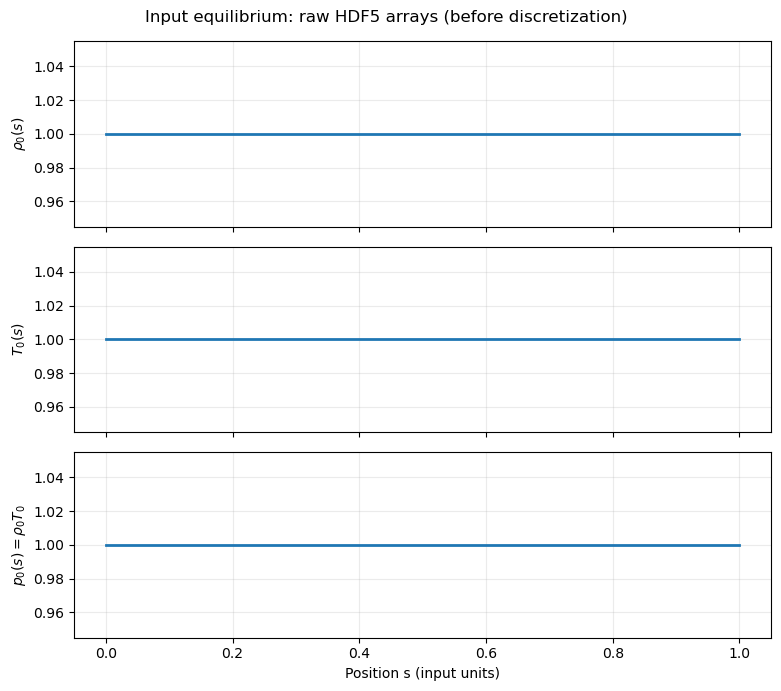

In [2]:
# Inspect the input equilibrium BEFORE constructing any finite-difference operators.
# These are the arrays loaded directly from the HDF5 file.
fig, axes = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
for ax, profile, name in zip(axes, [rho0, T0, p0],
                             [r'$\rho_0(s)$', r'$T_0(s)$', r'$p_0(s)=\rho_0T_0$']):
    ax.plot(s, profile, '-', lw=2)
    ax.set_ylabel(name)
    ax.grid(alpha=0.25)
axes[-1].set_xlabel('Position s (input units)')
fig.suptitle('Input equilibrium: raw HDF5 arrays (before discretization)')
plt.tight_layout()
plt.show()

## Interpolate the input equilibrium onto an independent solver grid

Choose `N` independently of the number of HDF5 samples. The raw arrays plotted above are preserved as `s_input`, `rho_input`, and `T_input`. Linear interpolation is used here (`np.interp`), without extrapolation. **This step must run before constructing the staggered operators.**

Input samples: 81 | Solver nodes: 81 | ds: 0.0125


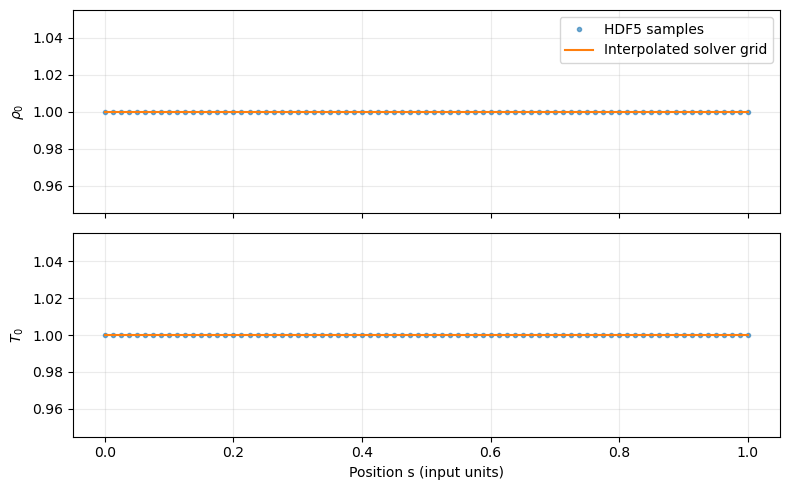

In [3]:
# Number of nodal points for the NMA solver (independent of the HDF5 resolution)
N = 81
if N < 6:
    raise ValueError('N must be at least 6 for the boundary stencils')

# Preserve the raw HDF5 data, then interpolate onto a uniform nodal grid.
s_input, rho_input, T_input = s.copy(), rho0.copy(), T0.copy()
s = np.linspace(s_input[0], s_input[-1], N)
rho0 = np.interp(s, s_input, rho_input)
T0 = np.interp(s, s_input, T_input)
p0 = rho0*T0
L = s[-1] - s[0]
ds = s[1] - s[0]
s_face = 0.5*(s[:-1] + s[1:])

print(f'Input samples: {len(s_input)} | Solver nodes: {N} | ds: {ds:.6g}')
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
for ax, raw, interp, label in zip(axes, [rho_input, T_input], [rho0, T0],
                                  [r'$\rho_0$', r'$T_0$']):
    ax.plot(s_input, raw, 'o', ms=3, alpha=0.6, label='HDF5 samples')
    ax.plot(s, interp, '-', lw=1.5, label='Interpolated solver grid')
    ax.set_ylabel(label)
    ax.grid(alpha=0.25)
axes[0].legend()
axes[-1].set_xlabel('Position s (input units)')
plt.tight_layout()
plt.show()

## Boundary conditions and staggered grid

The grid has $N$ density/temperature nodes (including physical endpoints) and $N-1$ interior velocity faces. Wall velocity is identically zero because wall velocities are not unknowns. Choose `BC = "line_tied"` for $T_1=0$ at the walls, or `BC = "reflecting"` for $\partial_s T_1=0$ and $\partial_s\rho_1=0$ at the walls. The reflecting density constraint is imposed through endpoint reconstruction, not by adding rows to a standard eigenproblem. The reflecting option is deliberately a *constrained toy model*; density Neumann conditions can overconstrain a compressible acoustic problem, so validate physical applicability before using it in research.

We construct a full operator on nodal variables and project it onto the allowed degrees of freedom. Endpoint temperature diffusion uses explicit boundary fluxes: zero for reflecting; fixed zero wall temperature for line-tied. This avoids relying on the velocity-divergence stencil as a thermal Laplacian.


In [4]:
def staggered_operators(N, ds):
    Dcf = np.zeros((N-1,N)); Icf = np.zeros((N-1,N))
    for j in range(N-1):
        Dcf[j,j] = -1/ds; Dcf[j,j+1] = 1/ds
        Icf[j,j:j+2] = 0.5
    Dfc = np.zeros((N,N-1))
    for j in range(1,N-1):
        Dfc[j,j-1] = -1/ds; Dfc[j,j] = 1/ds
    Dfc[0,0] = 3/ds; Dfc[0,1] = -1/(3*ds)
    Dfc[-1,-1] = -3/ds; Dfc[-1,-2] = 1/(3*ds)
    Ifc = np.zeros((N,N-1))
    Ifc[0,0] = 1.5; Ifc[0,1] = -0.5
    Ifc[-1,-1] = 1.5; Ifc[-1,-2] = -0.5
    for j in range(1,N-1): Ifc[j,j-1:j+1] = 0.5
    return Dcf,Dfc,Icf,Ifc

Dcf,Dfc,Icf,Ifc = staggered_operators(N,ds)

## 2. Equations and thermal physics

With perturbations $f_1(s)e^{nt}$ and $p_1=T_0\rho_1+\rho_0T_1$ (since $p=\rho T$):

$$n\rho_1=-\rho_0\partial_s v_1,$$
$$n v_1=-\rho_0^{-1}\partial_s p_1,$$
$$n T_1=-(\gamma-1)T_0\partial_s v_1-\frac{\gamma-1}{\rho_0}\left[\mathcal L_\rho\rho_1+\mathcal L_T T_1-\kappa\partial_s^2T_1\right].$$

Here $\mathcal L(\rho,T)=\rho^2\Lambda(T)-H$ is **volumetric net cooling** (positive = cooling). Choose $\Lambda(T)=\Lambda_0(T/T_\mathrm{ref})^\alpha$ and a constant background heating $H=\rho_0^2\Lambda(T_0)$; therefore $\mathcal L_0=0$. The derivatives at equilibrium are $\mathcal L_\rho=2\rho_0\Lambda(T_0)$ and $\mathcal L_T=\rho_0^2\Lambda(T_0)\alpha/T_0$. Constant $\kappa$ is used, so no background-gradient or $\kappa_T$ terms occur.

`lambda0=0` and `kappa=0` recover the adiabatic model. These are **toy dimensionless coefficients**, not a calibrated coronal loss function.

In [5]:
# Boundary selection: "line_tied" or "reflecting"
BC = "line_tied"

def bc_embedding(N, bc):
    """Return nodal reconstruction matrices for rho and T.

    Reflecting uses 2nd-order one-sided Neumann closure:
      (-3*f[0]+4*f[1]-f[2])/(2*ds)=0, and its right counterpart.
    Line-tied T endpoints are exactly zero; rho endpoints remain free.
    """
    if bc not in ('line_tied','reflecting'):
        raise ValueError('BC must be line_tied or reflecting')
    Rrho = np.eye(N) if bc == 'line_tied' else np.zeros((N,N-2))
    if bc == 'reflecting':
        Rrho[1:-1,:] = np.eye(N-2)
        Rrho[0,0],Rrho[0,1] = 4/3,-1/3
        Rrho[-1,-1],Rrho[-1,-2] = 4/3,-1/3
    RT = np.zeros((N,N-2)); RT[1:-1,:] = np.eye(N-2)
    if bc == 'reflecting':
        RT[0,0],RT[0,1] = 4/3,-1/3
        RT[-1,-1],RT[-1,-2] = 4/3,-1/3
    return Rrho,RT

def thermal_laplacian(N,ds,bc):
    """Second-order nodal Laplacian, evaluated only on interior T equations.
    Endpoint values are reconstructed by the selected BC embedding.
    """
    D2 = np.zeros((N-2,N))
    for i in range(1,N-1):
        D2[i-1,i-1:i+2] = [1,-2,1]
    return D2/ds**2

def build_matrix(rho0,T0,Dcf,Dfc,Icf,bc='reflecting',gamma=GAMMA,
                 lambda0=0.,alpha=-1.,kappa=0.,Tref=1.):
    N=len(rho0); nf=N-1; ds=s[1]-s[0]
    if lambda0<0 or kappa<0: raise ValueError('Coefficients must be nonnegative')
    Rrho,RT=bc_embedding(N,bc)
    # Selection of interior evolution equations (rho interior for reflecting).
    Srho=np.eye(N) if bc=='line_tied' else np.eye(N)[1:-1,:]
    ST=np.eye(N)[1:-1,:]
    rho_face=Icf@rho0
    Arv=-Dfc@np.diag(rho_face)
    Avr=-np.diag(1/rho_face)@Dcf@np.diag(T0)
    AvT=-np.diag(1/rho_face)@Dcf@np.diag(rho0)
    ATv=-(gamma-1)*np.diag(T0)@Dfc
    Lambda=lambda0*(T0/Tref)**alpha
    Lrho=2*rho0*Lambda; LT=rho0**2*Lambda*alpha/T0
    ATr=-np.diag((gamma-1)*Lrho/rho0)
    ATT=-np.diag((gamma-1)*LT/rho0)
    # Only the interior temperature rows are evolved; impose the thermal BC
    # through RT, and apply the conductive Laplacian on those rows.
    TT=ST@ATT@RT + np.diag((gamma-1)*kappa/rho0[1:-1])@thermal_laplacian(N,ds,bc)@RT
    nr=Rrho.shape[1]; nt=RT.shape[1]
    A=np.block([
      [np.zeros((nr,nr)),Srho@Arv,np.zeros((nr,nt))],
      [Avr@Rrho,np.zeros((nf,nf)),AvT@RT],
      [ST@ATr@Rrho,ST@ATv,TT]
    ])
    return A,(Rrho,RT)

def reconstruct_mode(vec,embedding):
    Rrho,RT=embedding; nr=Rrho.shape[1]; nf=N-1
    return Rrho@vec[:nr],vec[nr:nr+nf],RT@vec[nr+nf:]

def solve_nma(A): return eig(A)

A_adiabatic,embedding=build_matrix(rho0,T0,Dcf,Dfc,Icf,bc=BC)
evals_ad,vecs_ad=solve_nma(A_adiabatic)
print('BC:',BC,'matrix shape:',A_adiabatic.shape)


BC: line_tied matrix shape: (240, 240)


## 3. Arrange eigenvalues (adapted from the original helper)

Separate oscillatory acoustic modes from nonoscillatory entropy/thermal modes by $|\operatorname{Im}n|$; then label growth/damping by $\operatorname{Re}n$. **Zero eigenvalues are retained**: the adiabatic entropy perturbation is stationary, not necessarily spurious. Classification thresholds are scaled to the fundamental sound-crossing frequency.

In [6]:
def arrange_modes(evals, frequency_scale, tol=1e-5):
    cutoff = tol*frequency_scale
    thermal = np.flatnonzero(np.abs(evals.imag) <= cutoff)
    acoustic = np.flatnonzero(np.abs(evals.imag) > cutoff)
    growing = np.flatnonzero(evals.real > cutoff)
    damped = np.flatnonzero(evals.real < -cutoff)
    return {'thermal_or_entropy': thermal[np.argsort(evals[thermal].real)[::-1]],
            'acoustic': acoustic[np.argsort(np.abs(evals[acoustic].imag))],
            'growing': growing[np.argsort(evals[growing].real)[::-1]],
            'damped': damped[np.argsort(evals[damped].real)]}

cs=np.sqrt(GAMMA*T0[0]); scale=np.pi*cs/L
m_ad=arrange_modes(evals_ad,scale)
print({k:len(v) for k,v in m_ad.items()})
print('Adiabatic max |Re(n)|:',np.max(np.abs(evals_ad.real)))

{'thermal_or_entropy': 80, 'acoustic': 160, 'growing': 0, 'damped': 0}
Adiabatic max |Re(n)|: 6.81728504485675e-14


## 4. Acoustic sanity check

For rigid walls, the homogeneous adiabatic continuum gives $\omega_m=m\pi c_s/L$. Compare the first few positive-frequency numerical modes. Discrete wall closure introduces finite-resolution error.

In [7]:
positive=np.sort(evals_ad.imag[evals_ad.imag>1e-5*scale])
for m in range(1,min(5,len(positive))+1):
    exact=m*np.pi*cs/L
    print(f'm={m}: numerical={positive[m-1]:.6f}, analytic={exact:.6f}, relative error={abs(positive[m-1]-exact)/exact:.2%}')

m=1: numerical=4.030344, analytic=4.055779, relative error=0.63%
m=2: numerical=8.059224, analytic=8.111557, relative error=0.65%
m=3: numerical=12.085178, analytic=12.167336, relative error=0.68%
m=4: numerical=16.106741, analytic=16.223115, relative error=0.72%
m=5: numerical=20.122450, analytic=20.278893, relative error=0.77%


## Plot acoustic eigenfunctions (adiabatic reference)

Select the positive-frequency acoustic branches and compare the first few standing-wave eigenfunctions. We rotate the arbitrary complex phase using the velocity component, and normalize each variable independently. The dashed curves show the imaginary part; conjugate modes have the same physical standing-wave structure. Note that stationary entropy modes remain in the spectrum and are **not** acoustic modes.

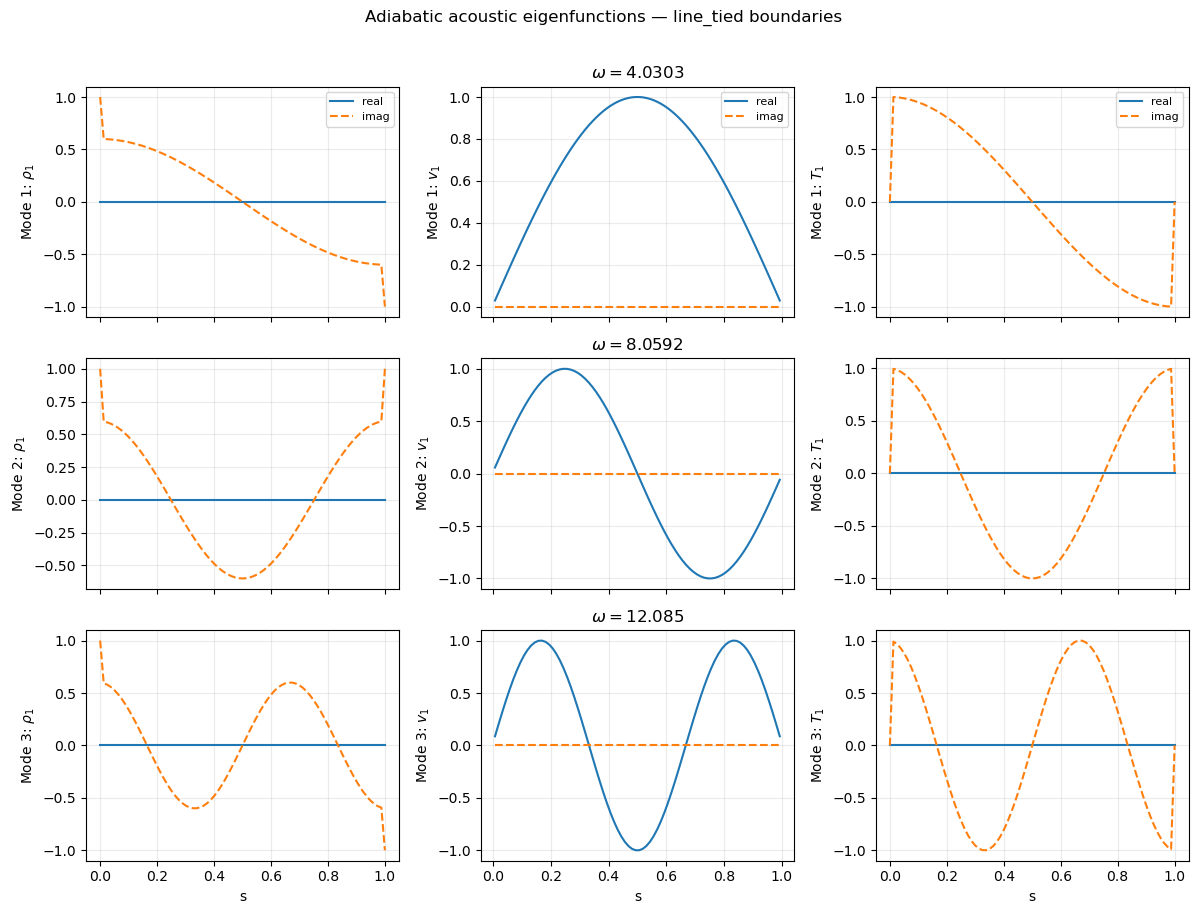

In [8]:
# Plot the first three positive-frequency acoustic modes from the adiabatic solve.
positive_idx = np.flatnonzero(evals_ad.imag > 1e-5*scale)
positive_idx = positive_idx[np.argsort(evals_ad[positive_idx].imag)]
n_show = min(3, len(positive_idx))
if n_show == 0:
    print('No positive-frequency acoustic modes found.')
else:
    fig, axes = plt.subplots(n_show, 3, figsize=(12, 3*n_show), squeeze=False,
                             sharex='col')
    for row, idx in enumerate(positive_idx[:n_show]):
        r, v, temp = reconstruct_mode(vecs_ad[:, idx].copy(), embedding)
        anchor = v if np.max(np.abs(v)) > 1e-12 else r
        phase = np.exp(-1j*np.angle(anchor[np.argmax(np.abs(anchor))]))
        for col, (xx, y, name) in enumerate(zip(
                (s, s_face, s), (r*phase, v*phase, temp*phase),
                (r'$\rho_1$', r'$v_1$', r'$T_1$'))):
            amplitude = max(np.max(np.abs(y)), 1e-30)
            axes[row,col].plot(xx, y.real/amplitude, label='real')
            axes[row,col].plot(xx, y.imag/amplitude, '--', label='imag')
            axes[row,col].set_ylabel(f'Mode {row+1}: {name}')
            axes[row,col].grid(alpha=0.25)
            if row == 0: axes[row,col].legend(fontsize=8)
        axes[row,1].set_title(r'$\omega = %.5g$' % evals_ad[idx].imag)
    for ax in axes[-1]: ax.set_xlabel('s')
    fig.suptitle(f'Adiabatic acoustic eigenfunctions — {BC} boundaries', y=1.01)
    plt.tight_layout()
    plt.show()

## 5. Add radiative losses and conduction

The cooling exponent $\alpha=-1$ is deliberately thermally destabilizing for this illustrative loss function. Conduction stabilizes sufficiently short wavelengths. Experiment with `lambda0`, `alpha`, and `kappa` to see the eigenvalue spectrum change. A positive real part means growth because perturbations vary as $e^{nt}$.

{'thermal_or_entropy': 80, 'acoustic': 160, 'growing': 3, 'damped': 236}
Largest growth rate: 0.13256097204203407


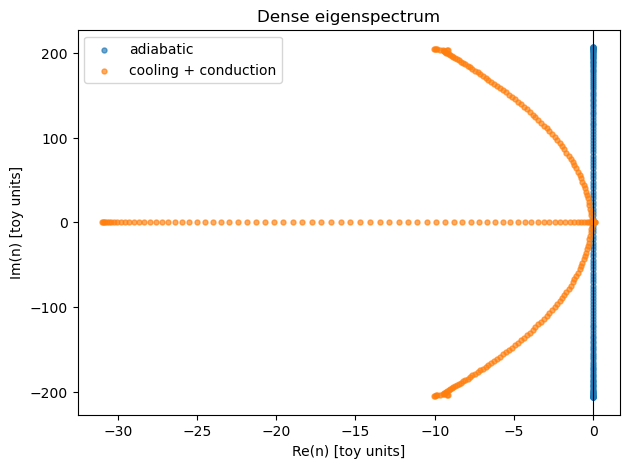

In [9]:
lambda0 = 0.15
alpha = -1.0
kappa = 0.003
A_thermal,_ = build_matrix(rho0,T0,Dcf,Dfc,Icf,bc=BC,lambda0=lambda0,alpha=alpha,kappa=kappa)
evals_th,vecs_th=solve_nma(A_thermal)
m_th=arrange_modes(evals_th,scale)
print({k:len(v) for k,v in m_th.items()})
print('Largest growth rate:',np.max(evals_th.real))
fig,ax=plt.subplots(figsize=(7,5))
ax.scatter(evals_ad.real,evals_ad.imag,s=13,alpha=.65,label='adiabatic')
ax.scatter(evals_th.real,evals_th.imag,s=13,alpha=.65,label='cooling + conduction')
ax.axvline(0,color='k',lw=.8); ax.set(xlabel='Re(n) [toy units]',ylabel='Im(n) [toy units]',title='Dense eigenspectrum')
ax.legend();plt.show()

## 6. Inspect the fastest growing eigenfunction

An eigenvector has arbitrary amplitude and complex phase. Rotate it so the largest temperature component is real, and normalize each variable independently for display. The velocity eigenfunction lives on the interior-face grid.

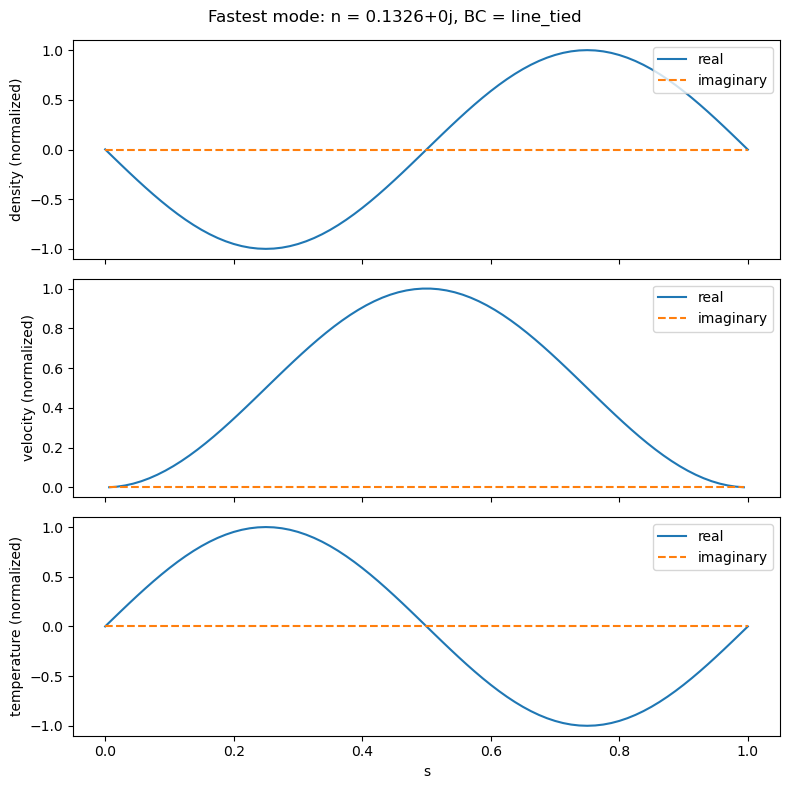

In [10]:
# Reconstruct complete nodal eigenfunctions, including boundary values.
i = np.argmax(evals_th.real)
vec = vecs_th[:, i].copy()
r1, v1, T1 = reconstruct_mode(vec, embedding)
anchor = T1 if np.max(np.abs(T1)) > 1e-12 else r1
vec *= np.exp(-1j*np.angle(anchor[np.argmax(np.abs(anchor))]))
r1, v1, T1 = reconstruct_mode(vec, embedding)
fig, axs = plt.subplots(3, 1, figsize=(8, 8), sharex=True)
for ax, xx, y, label in zip(axs, [s, s_face, s], [r1, v1, T1],
                            ['density', 'velocity', 'temperature']):
    amplitude = max(np.max(np.abs(y)), 1e-30)
    ax.plot(xx, y.real/amplitude, label='real')
    ax.plot(xx, y.imag/amplitude, '--', label='imaginary')
    ax.set_ylabel(label+' (normalized)')
    ax.legend(loc='upper right')
axs[-1].set_xlabel('s')
fig.suptitle(f'Fastest mode: n = {evals_th[i]:.4g}, BC = {BC}')
plt.tight_layout()
plt.show()

## Notes for adapting to custom files

* Supply a 1D **uniform equilibrium** via an HDF5 file with datasets `/s`, `/rho0`, `/T0`, all of the same length. Edit `INPUT_FILE` at the top. For NumPy arrays, replace `load_background` with your arrays directly.
* For **real coronal loops**, restore the equilibrium flow, gravity, area expansion, heating/cooling derivatives, Spitzer conductivity and physical normalization from the full NMA notebook; this tutorial does not model those effects.
* The boundary stencils are intentionally close to the original implementation. For quantitative convergence studies, verify the wall closures and convergence of the thermal eigenvalues separately. The toy setup is for pedagogy.

In [11]:
# Explicit boundary residual test on a reconstructed eigenvector
j = np.argmax(evals_ad.real)
rho1,v1,T1 = reconstruct_mode(vecs_ad[:,j],embedding)
print('Wall velocities:',0.,0.)
if BC == 'line_tied':
    print('Wall temperatures:',T1[0],T1[-1])
else:
    grad=lambda f: ((-3*f[0]+4*f[1]-f[2])/(2*ds),
                    (3*f[-1]-4*f[-2]+f[-3])/(2*ds))
    print('rho Neumann residuals:',grad(rho1))
    print('T Neumann residuals:',grad(T1))

Wall velocities: 0.0 0.0
Wall temperatures: 0j 0j


## Diagnostic: equation residuals and boundary closure
For an acoustic eigenpair, compare the reconstructed fields with the **full, unreduced** adiabatic equations. Interior residuals should be near machine precision. The line-tied temperature equation is not evolved at the endpoints; its endpoint residuals are therefore reported separately, not counted as enforced equations. The density equation is evolved at the endpoints for `line_tied`, so its boundary residual is particularly informative.

BC=line_tied, acoustic eigenvalue n=1.6090254e-15+4.0303436j
Continuity interior relative residual: 2.4273695586250745e-14
Continuity endpoint residuals: [ 1.02872765e-15-6.55031585e-15j -3.23625050e-16+7.10542736e-15j]
Momentum relative residual: 3.1307504663138044e-14
Temperature interior relative residual: 2.2606428766450604e-14
Temperature endpoint residuals (not enforced): [-4.60545678e-16-0.39485705j -5.81121057e-17+0.39485705j]


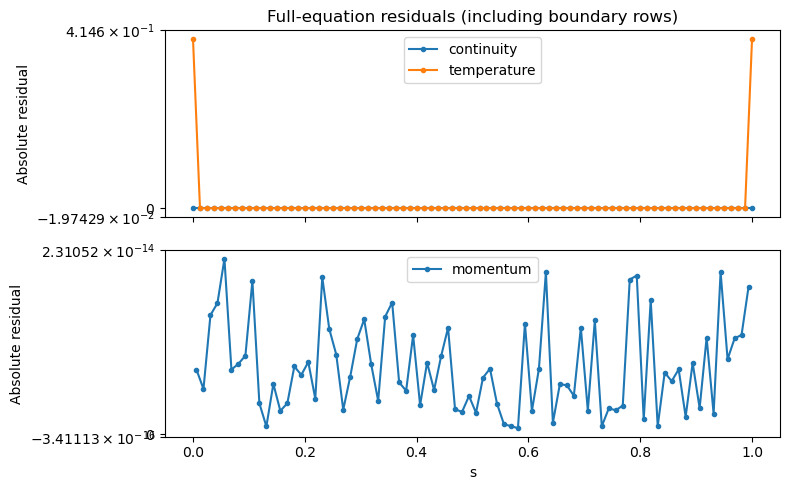

In [12]:
# Test the first positive-frequency adiabatic acoustic mode.
idx = np.flatnonzero(evals_ad.imag > 1e-6 * scale)
j = idx[np.argmin(evals_ad.imag[idx])]
n = evals_ad[j]
r1, v1, t1 = reconstruct_mode(vecs_ad[:, j], embedding)

rho_face = Icf @ rho0
# Full adiabatic linearized equations, including endpoint rows.
Rrho = n*r1 + Dfc @ (rho_face*v1)
Rv = n*v1 + (Dcf @ (T0*r1 + rho0*t1))/rho_face
RT = n*t1 + (GAMMA-1)*T0*(Dfc @ v1)

def rel_norm(res, *terms):
    return np.linalg.norm(res) / max(*(np.linalg.norm(x) for x in terms), 1e-14)

print(f'BC={BC}, acoustic eigenvalue n={n:.8g}')
print('Continuity interior relative residual:', rel_norm(Rrho[1:-1], n*r1[1:-1], (Dfc@(rho_face*v1))[1:-1]))
print('Continuity endpoint residuals:', Rrho[[0,-1]])
print('Momentum relative residual:', rel_norm(Rv, n*v1, (Dcf@(T0*r1+rho0*t1))/rho_face))
print('Temperature interior relative residual:', rel_norm(RT[1:-1], n*t1[1:-1], ((GAMMA-1)*T0*(Dfc@v1))[1:-1]))
print('Temperature endpoint residuals (not enforced):', RT[[0,-1]])

fig, ax = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
ax[0].plot(s, np.abs(Rrho), '.-', label='continuity')
ax[0].plot(s, np.abs(RT), '.-', label='temperature')
ax[0].set(ylabel='Absolute residual', yscale='symlog', title='Full-equation residuals (including boundary rows)')
ax[0].legend()
ax[1].plot(s_face, np.abs(Rv), '.-', label='momentum')
ax[1].set(xlabel='s', ylabel='Absolute residual', yscale='symlog')
ax[1].legend()
plt.tight_layout(); plt.show()

### A note on boundary conditions in the adiabatic limit

The notebook provides two options for boundary conditions:

**Reflecting boundaries:**

$$
v_1 = 0, \qquad
\frac{\partial \rho_1}{\partial s} = 0, \qquad
\frac{\partial T_1}{\partial s} = 0
$$

**Line-tied boundaries:**

$$
v_1 = 0, \qquad T_1 = 0
$$

For a homogeneous plasma in the adiabatic limit, the linearized temperature equation is

$$
nT_1 = -(\gamma-1)T_0\frac{\partial v_1}{\partial s}.
$$

For nonzero-frequency acoustic modes, imposing $T_1=0$ at the boundaries would therefore also require

$$
\frac{\partial v_1}{\partial s}=0.
$$

However, the usual standing acoustic waves satisfying $v_1=0$ at both ends have

$$
v_1(s)\propto\sin\left(\frac{m\pi s}{L}\right),
$$

whose spatial derivative is generally nonzero at the boundaries.

Consequently, imposing both $v_1=0$ and $T_1=0$ is incompatible with these nontrivial standing acoustic solutions in the strictly adiabatic, homogeneous limit.

In the numerical implementation, the temperature equation is replaced by the prescribed Dirichlet conditions at the endpoints. The resulting acoustic eigenfunctions satisfy the interior equations to machine precision but may exhibit sharp changes in temperature near the boundaries. These features should not be interpreted as physical boundary layers in the adiabatic problem.

When thermal conduction is included, the temperature equation contains an additional second-order spatial derivative,

$$
nT_1 =
-(\gamma-1)T_0\frac{\partial v_1}{\partial s}
+\frac{(\gamma-1)\kappa}{\rho_0}
\frac{\partial^2T_1}{\partial s^2}
+\text{radiative terms}.
$$

The conductive term allows temperature boundary layers to develop, making the Dirichlet temperature conditions compatible with nontrivial solutions.

**For this reason, reflecting boundaries are recommended for validating the adiabatic acoustic modes against analytical solutions, whereas line-tied boundaries can be used for the nonadiabatic problem with thermal conduction.** In the latter case, numerical convergence of both the eigenvalues and eigenfunctions should be verified.